# Stack Overflow Developer Salary Analysis

This self-contained notebook starts with the original Stack Overflow survey downloads, harmonizes both years, and carries out descriptive, predictive, and prescriptive salary analysis. In Google Colab, upload the two raw CSVs into the same working directory as the notebook; no raw-data subfolder is needed. The accepted filename pairs are `results.csv` + `survey_results_public.csv`, or `2025_raw.csv` + `2026_raw.csv`.

## Run order

1. Install the listed Python packages in the notebook environment.
2. In Google Colab, upload the raw 2025 and 2026 CSVs into the notebook's working directory, then run top to bottom. The notebook also supports the repository's local `unharmonized_raw_data/` folder. Preprocessing runs **2026 first**, then 2025.
3. The preprocessing cells write harmonized `2026.csv` and `2025.csv` at the `Workbook` root, plus `harmonized_schema.csv`. Later cells create tables and charts under `outputs/`.
4. The predictive section tunes the random forest and fits linear regression using 2025 data, then compares both on 2026 data.

The notebook writes harmonized data and its schema into the current working directory, and creates `outputs/` automatically for tables and charts.

## 1. Packages and paths

This section imports the data, plotting, and machine learning libraries and prepares an output directory. Install any missing packages in your environment before continuing.

In [1]:
from pathlib import Path
import json
import textwrap
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (mean_absolute_error, mean_squared_error, median_absolute_error, r2_score,
    accuracy_score, balanced_accuracy_score, precision_recall_fscore_support, confusion_matrix)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
ROOT = Path.cwd()
filename_pairs = [("results.csv", "survey_results_public.csv"),
                  ("2025_raw.csv", "2026_raw.csv")]
RAW_DIR = ROOT
selected_pair = next((pair for pair in filename_pairs
                      if all((ROOT / name).exists() for name in pair)), None)
if selected_pair is None and (ROOT / "unharmonized_raw_data").exists():
    RAW_DIR = ROOT / "unharmonized_raw_data"
    selected_pair = next((pair for pair in filename_pairs
                          if all((RAW_DIR / name).exists() for name in pair)), None)
if selected_pair is None:
    candidates = [ROOT / "Workbook", ROOT / "workbook"]
    workbook = next((folder for folder in candidates
                     if (folder / "unharmonized_raw_data").exists()), None)
    if workbook is not None:
        ROOT = workbook
        RAW_DIR = ROOT / "unharmonized_raw_data"
        selected_pair = next((pair for pair in filename_pairs
                              if all((RAW_DIR / name).exists() for name in pair)), None)
if selected_pair is None:
    raise FileNotFoundError("Upload results.csv and survey_results_public.csv (or 2025_raw.csv and 2026_raw.csv) beside the notebook.")
RAW_2025 = RAW_DIR / selected_pair[0]
RAW_2026 = RAW_DIR / selected_pair[1]
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
print("Workbook folder:", ROOT.resolve())
print("Outputs folder:", OUT.resolve())

Workbook folder: /Users/aviralaman/Documents/GitHub/salary-predictor-analytics/workbook
Outputs folder: /Users/aviralaman/Documents/GitHub/salary-predictor-analytics/workbook/outputs


## 2. Harmonization rules

The survey uses different names for several equivalent fields in each year. This section maps those source columns to a shared schema, normalizes role and skill labels, converts numeric fields, and defines the professional developer and employed indicators. The same rules are used for both years so later comparisons are consistent.

In [2]:
# Canonical field name -> source field in each raw survey.
SPECS = {
    2025: {
        "file": RAW_2025, "dev_value": "I am a developer by profession",
        "columns": {"response_id":"ResponseId", "dev":"MainBranch", "employment":"Employment",
            "country":"Country", "industry":"Industry", "salary":"ConvertedCompYearly", "age":"Age", "work_exp":"WorkExp",
            "years_code":"YearsCode", "role":"DevType", "education":"EdLevel", "org_size":"OrgSize",
            "work_setting":"RemoteWork", "tool_count":"ToolCountWork", "lang":"LanguageHaveWorkedWith",
            "db":"DatabaseHaveWorkedWith", "web":"WebframeHaveWorkedWith",
            "ide":"DevEnvsHaveWorkedWith", "cloud":"PlatformHaveWorkedWith"}},
    2026: {
        "file": RAW_2026, "dev_value": "I create code as a primary part of my job",
        "columns": {"response_id":"ResponseId", "dev":"CodeMain", "employment":"Employment",
            "country":"Country", "industry":"Industry", "salary":"ConvertedCompYearly", "age":"Age", "work_exp":"WorkExp",
            "years_code":"YearsCode", "role":"Role", "education":"Education", "org_size":"OrgSize",
            "work_setting":"WorkSetting", "tool_count":"ToolCount", "lang":"LanguagesHaveWorkedWith",
            "db":"DatabasesHaveWorkedWith", "web":"WebFrameworkHaveWorkedWith",
            "ide":"DevIDEHaveWorkedWith", "cloud":"CloudPlatHaveWorkedWith"}}
}

ROLE_GROUPS = {
    "Full-stack developer":["Developer, full-stack"],
    "Back-end developer":["Developer, back-end"],
    "Front-end developer":["Developer, front-end"],
    "Mobile developer":["Developer, mobile"],
    "Desktop/enterprise developer":["Developer, desktop or enterprise applications"],
    "Game/graphics developer":["Developer, game or graphics"],
    "Embedded/hardware":["Developer, embedded applications or devices", "Hardware engineer"],
    "QA/test":["Developer, QA or test"],
    "Data, analytics and AI":["Data engineer", "Data scientist", "AI/ML engineer", "Applied scientist",
        "Developer, AI apps or physical AI", "Data or business analyst", "Financial analyst or engineer"],
    "DevOps/cloud/platform":["DevOps engineer or professional", "Cloud infrastructure engineer",
        "Site reliability engineer", "Platform engineer"],
    "IT, security and admin":["System administrator", "Database administrator or engineer",
        "Cybersecurity or InfoSec professional"],
    "Architect":["Architect, software or solutions"],
    "Management":["Engineering manager", "Senior executive (C-suite, VP, etc.)", "Founder, technology or otherwise",
        "Founder or entrepreneur", "Project manager", "Product manager"],
    "Other roles":["Other (please specify):", "Other", "Academic researcher", "Educator or instructor", "Student",
        "Retired", "Support engineer or analyst", "UX, Research Ops or UI design professional",
        "UX, research, or UI design professional", "Solutions engineer, implementation engineer, or forward-deployed engineer",
        "Software engineer", "Developer advocate or developer relations professional",
        "Technical writer or documentation professional", "Marketing/Sales professional"]}
ROLE_MAP = {label.lower(): group for group, labels in ROLE_GROUPS.items() for label in labels}
SKILL_ALIASES = {"docker / docker compose":"docker", "digital ocean":"digitalocean", "maven (build tool)":"maven"}
AGE_MAX_EXP = {"Under 18 years old":2, "18-24 years old":8, "25-34 years old":18,
    "35-44 years old":28, "45-54 years old":38, "55-64 years old":48,
    "65 years or older":55, "Prefer not to say":50}
AGE_OK = [age for age in AGE_MAX_EXP if age != "Under 18 years old"]
SALARY_RANGE = (1_000, 500_000)
SKILL_FIELDS = ["lang_list", "db_list", "web_list", "ide_list", "cloud_list"]

print("Harmonized skill families:", SKILL_FIELDS)
print("Role groups:", len(ROLE_GROUPS))

Harmonized skill families: ['lang_list', 'db_list', 'web_list', 'ide_list', 'cloud_list']
Role groups: 14


## 3. Reusable preprocessing function

The function below reads only the fields needed for this analysis from a raw survey CSV. It standardizes the column names, groups detailed job titles into broader roles, harmonizes skill-list text, and preserves all respondent rows in the preprocessed file. Eligibility flags are added for later descriptive and predictive analysis; they do not delete raw respondents.

In [3]:
def clean_text(value):
    return str(value).replace("’", "'").strip()

def clean_skill_list(value):
    items = []
    for item in str(value).split(";"):
        key = clean_text(item).lower()
        key = SKILL_ALIASES.get(key, key)
        if key and not key.startswith("other") and key not in items:
            items.append(key)
    return ";".join(items)

def education_group(value):
    x = clean_text(value).lower()
    for prefix, group in [("primary", "Secondary or less"), ("secondary", "Secondary or less"),
        ("some college", "Some college"), ("associate", "Associate"), ("bachelor", "Bachelor's"),
        ("master", "Master's"), ("professional", "Doctorate/professional")]:
        if x.startswith(prefix):
            return group
    return "Other"

def normalize_industry(value):
    text = clean_text(value)
    if not text:
        return "Not stated"
    key = text.casefold()
    aliases = {
        "other:": "Other/unspecified", "other, please specify": "Other/unspecified",
        "software development": "Software development",
        "banking/financial services": "Banking and financial services",
        "computer systems design and services": "IT services and systems integration",
        "it services, consulting, systems integration, or managed services": "IT services and systems integration",
        "higher education": "Education", "education": "Education",
        "media & advertising services": "Media and advertising",
        "media or advertising services": "Media and advertising",
        "retail and consumer services": "Retail and consumer services",
        "retail, e-commerce, or consumer services": "Retail and consumer services",
        "transportation, or supply chain": "Transportation and supply chain",
        "transportation or supply chain": "Transportation and supply chain",
    }
    return aliases.get(key, text)

def preprocess_year(year):
    spec = SPECS[year]
    colmap = spec["columns"]
    raw = pd.read_csv(spec["file"], usecols=list(colmap.values()), dtype=str,
                      keep_default_na=False, low_memory=False)
    raw = raw.replace("NA", "")
    source = pd.DataFrame({key: raw[source_col].astype(str).str.strip()
                           for key, source_col in colmap.items()})
    d = pd.DataFrame(index=source.index)
    d["year"] = year
    d["id"] = str(year) + "_" + source["response_id"]
    d["is_developer"] = source["dev"].eq(spec["dev_value"]).astype("int8")
    d["is_employed"] = source["employment"].eq("Employed").astype("int8")
    d["country"] = source["country"].replace({"United Kingdom of Great Britain and Northern Ireland":"United Kingdom"})
    d["industry"] = source["industry"].map(normalize_industry)
    d["salary_usd"] = pd.to_numeric(source["salary"].replace("", np.nan), errors="coerce")
    d["age"] = source["age"].replace("", "Not stated")
    for col in ["work_exp", "years_code", "tool_count_raw"]:
        raw_col = {"work_exp":"work_exp", "years_code":"years_code", "tool_count_raw":"tool_count"}[col]
        d[col] = pd.to_numeric(source[raw_col].replace("", np.nan), errors="coerce")
    d["role_group"] = source["role"].str.lower().map(ROLE_MAP).fillna("Other roles")
    d["education"] = source["education"].map(education_group)
    d["org_size"] = source["org_size"].map(lambda x: clean_text(x) or "Not stated")
    d["work_setting"] = source["work_setting"].map(lambda x: clean_text(x) or "Not stated")
    for family in ["lang", "db", "web", "ide", "cloud"]:
        d[f"{family}_list"] = source[family].map(clean_skill_list)

    # A consistent eligibility flag used for salary analysis and modeling.
    age_limit = d["age"].map(AGE_MAX_EXP)
    eligible = (d["is_developer"].eq(1) & d["is_employed"].eq(1) & d["country"].ne("") &
        d["salary_usd"].between(*SALARY_RANGE) & d["age"].isin(AGE_OK) &
        ~(d["work_exp"] > age_limit) & d["years_code"].notna())
    d["in_model"] = eligible.astype("int8")
    d["has_salary"] = d["salary_usd"].notna().astype("int8")
    d["work_exp_blank"] = d["work_exp"].isna().astype("int8")
    d.loc[d["in_model"].eq(1) & d["work_exp"].isna(), "work_exp"] = 0
    d["tool_count"] = d["tool_count_raw"].where(d["tool_count_raw"] > 0).clip(upper=50)
    return d

print("Preprocessing function is ready. It keeps raw respondent rows and adds an analysis eligibility flag.")

Preprocessing function is ready. It keeps raw respondent rows and adds an analysis eligibility flag.


## 4. Preprocess 2026 first

Run this cell first to harmonize the 2026 raw survey. The resulting shared-schema `2026.csv` is saved directly inside `Workbook`.

In [4]:
df_2026 = preprocess_year(2026)
path_2026 = ROOT / "2026.csv"
df_2026.to_csv(path_2026, index=False)
print(f"2026: {len(df_2026):,} respondents; {int(df_2026.in_model.sum()):,} eligible for salary modeling")
print("Saved:", path_2026.name)
display(df_2026.head())

2026: 30,903 respondents; 8,784 eligible for salary modeling
Saved: 2026.csv


,year,id,is_developer,is_employed,country,industry,salary_usd,age,work_exp,years_code,...,work_setting,lang_list,db_list,web_list,ide_list,cloud_list,in_model,has_salary,work_exp_blank,tool_count
0,2026,2026_1,1,0,Sri Lanka,Education,NaN,35-44 years old,NaN,NaN,...,"Hybrid (some remote, leans heavy to in-person)",,mysql;postgresql;sqlite,,,,0,0,1,NaN
1,2026,2026_2,1,1,Brazil,Government,NaN,45-54 years old,26.0,28.0,...,Remote,,oracle;postgresql,,,,0,0,0,5.0
2,2026,2026_3,1,0,Ukraine,Not stated,10000.0,65 years or older,37.0,20.0,...,Not stated,,,,,,0,1,0,NaN
3,2026,2026_4,1,0,United States of America,Not stated,NaN,Under 18 years old,1.0,7.0,...,Not stated,bash/shell (all shells);c++;groovy;html/css;ja...,cloud firestore;mongodb;postgresql;redis;sqlit...,deno;django;express;fastapi;jquery;next.js;nod...,intellij idea;visual studio code,chocolatey;cloudflare;docker;firebase;gradle;n...,0,0,0,NaN
4,2026,2026_5,1,1,Germany,Software development,85296.0,45-54 years old,26.0,30.0,...,Remote,,,,clion;notepad++;visual studio,,1,1,0,4.0


## 5. Preprocess 2025 second

Apply the same normalization rules to the 2025 raw survey and save `2025.csv`. Both year files now share the same canonical columns.

In [5]:
df_2025 = preprocess_year(2025)
path_2025 = ROOT / "2025.csv"
df_2025.to_csv(path_2025, index=False)
print(f"2025: {len(df_2025):,} respondents; {int(df_2025.in_model.sum()):,} eligible for salary modeling")
print("Saved:", path_2025.name)
assert list(df_2025.columns) == list(df_2026.columns)
print("Schema check passed:", len(df_2025.columns), "shared columns")
display(df_2025.head())

2025: 49,191 respondents; 16,337 eligible for salary modeling
Saved: 2025.csv
Schema check passed: 24 shared columns


,year,id,is_developer,is_employed,country,industry,salary_usd,age,work_exp,years_code,...,work_setting,lang_list,db_list,web_list,ide_list,cloud_list,in_model,has_salary,work_exp_blank,tool_count
0,2025,2025_1,1,1,Ukraine,Fintech,61256.0,25-34 years old,8.0,14.0,...,Remote,bash/shell (all shells);dart;sql,cloud firestore;postgresql,,android studio;notepad++;visual studio;visual ...,amazon web services (aws);cloudflare;firebase;...,1,1,0,7.0
1,2025,2025_2,1,1,Netherlands,Retail and consumer services,104413.0,25-34 years old,2.0,10.0,...,"Hybrid (some in-person, leans heavy to flexibi...",java,dynamodb;mongodb,spring boot,intellij idea;pycharm;visual studio code;xcode,amazon web services (aws);datadog;docker;homeb...,1,1,0,6.0
2,2025,2025_3,1,0,Ukraine,Software development,53061.0,35-44 years old,10.0,12.0,...,Not stated,dart;html/css;javascript;typescript,mongodb;mysql;postgresql,next.js;node.js;react,visual studio code,datadog;firebase;npm;pnpm,0,1,0,3.0
3,2025,2025_4,1,1,Ukraine,Retail and consumer services,36197.0,35-44 years old,4.0,5.0,...,Remote,java;kotlin;sql,,spring boot,,amazon web services (aws);google cloud,1,1,0,NaN
4,2025,2025_5,1,0,Ukraine,Software development,60000.0,35-44 years old,21.0,22.0,...,Not stated,c;c#;c++;delphi;html/css;java;javascript;lua;p...,elasticsearch;microsoft sql server;mysql;oracl...,angular;asp.net;asp.net core;flask;jquery,eclipse;intellij idea;jupyter notebook/jupyter...,amazon web services (aws);apt;docker;make;mave...,0,1,0,4.0


## 6. Shared output schema

Both harmonized files use the same named columns and order. The schema reference records the meaning of each field and which original field it came from in each survey. In particular, `salary_usd` uses Stack Overflow’s `ConvertedCompYearly` value in both years; the respondent’s original currency/compensation pair is not mixed into that prediction target.

In [6]:
OUTPUT_DESCRIPTIONS = {
    "year":"Survey year.", "id":"Year-prefixed public response identifier.",
    "is_developer":"1 if the respondent selected the year-specific professional developer option.",
    "is_employed":"1 if employment status is Employed.", "country":"Country, with the UK label standardized.",
    "industry":"Normalized company-industry category from the survey.",
    "salary_usd":"Annual compensation converted to USD by the survey; sourced from ConvertedCompYearly.",
    "age":"Reported age band.", "work_exp":"Reported years of professional work experience.",
    "years_code":"Reported years coding.", "role_group":"Role mapped to a shared role group.",
    "education":"Education label grouped into shared categories.", "org_size":"Reported organization size.",
    "work_setting":"Reported work setting.", "tool_count_raw":"Raw survey count of tools/technologies used.",
    "lang_list":"Normalized semicolon-delimited programming language list.",
    "db_list":"Normalized semicolon-delimited database list.",
    "web_list":"Normalized semicolon-delimited web framework list.",
    "ide_list":"Normalized semicolon-delimited IDE list.",
    "cloud_list":"Normalized semicolon-delimited cloud/platform list.",
    "in_model":"1 if the row meets the shared salary-model eligibility criteria.",
    "has_salary":"1 if ConvertedCompYearly is present.",
    "work_exp_blank":"1 if reported professional work experience is missing.",
    "tool_count":"Tool count, positive values only and capped at 50."}
SOURCE_KEYS = {"id":"response_id", "is_developer":"dev", "is_employed":"employment",
               "salary_usd":"salary", "industry":"industry", "has_salary":"salary", "work_exp_blank":"work_exp",
               "role_group":"role", "education":"education",
               "tool_count_raw":"tool_count", "lang_list":"lang", "db_list":"db",
               "web_list":"web", "ide_list":"ide", "cloud_list":"cloud", "tool_count":"tool_count"}
schema_rows = []
for position, field in enumerate(df_2025.columns, start=1):
    key = SOURCE_KEYS.get(field, field)
    derived_rule = field == "in_model"
    source_2025 = "Derived eligibility rules" if derived_rule else SPECS[2025]["columns"].get(key, "Derived" if field == "year" else "")
    source_2026 = "Derived eligibility rules" if derived_rule else SPECS[2026]["columns"].get(key, "Derived" if field == "year" else "")
    schema_rows.append({
        "column_number":position, "harmonized_column":field,
        "source_column_2025":source_2025, "source_column_2026":source_2026,
        "description":OUTPUT_DESCRIPTIONS.get(field, "Normalized survey field."),
        "data_type":str(df_2025[field].dtype)})
harmonized_schema = pd.DataFrame(schema_rows)
harmonized_schema.to_csv(ROOT / "harmonized_schema.csv", index=False)
assert df_2025.columns.tolist() == df_2026.columns.tolist()
print("Saved shared schema with", len(harmonized_schema), "fields")
display(harmonized_schema)

Saved shared schema with 24 fields


,column_number,harmonized_column,source_column_2025,source_column_2026,description,data_type
0,1,year,Derived,Derived,Survey year.,int64
1,2,id,ResponseId,ResponseId,Year-prefixed public response identifier.,str
2,3,is_developer,MainBranch,CodeMain,1 if the respondent selected the year-specific...,int8
3,4,is_employed,Employment,Employment,1 if employment status is Employed.,int8
4,5,country,Country,Country,"Country, with the UK label standardized.",str
5,6,industry,Industry,Industry,Normalized company-industry category from the ...,str
6,7,salary_usd,ConvertedCompYearly,ConvertedCompYearly,Annual compensation converted to USD by the su...,float64
7,8,age,Age,Age,Reported age band.,str
8,9,work_exp,WorkExp,WorkExp,Reported years of professional work experience.,float64
9,10,years_code,YearsCode,YearsCode,Reported years coding.,float64


### Reload point for continuing in a fresh kernel

This cell reads the completed harmonized files while preserving empty skill-list values as empty strings. Use it to resume analysis without rerunning the raw-data preprocessing cells.

In [7]:
df_2025 = pd.read_csv(ROOT / "2025.csv", keep_default_na=False, low_memory=False)
df_2026 = pd.read_csv(ROOT / "2026.csv", keep_default_na=False, low_memory=False)

UNKNOWN_LABELS = {"not stated", "i don't know"}
UNKNOWN_FIELDS = [
    "country", "age", "role_group", "education",
    "org_size", "work_setting", "industry",
]

for frame in (df_2025, df_2026):
    for column in UNKNOWN_FIELDS:
        label = frame[column].astype("string").str.strip().str.casefold()
        frame.loc[label.isin(UNKNOWN_LABELS), column] = np.nan

NUMERIC_OUTPUTS = ["year", "is_developer", "is_employed", "salary_usd", "work_exp",
                   "years_code", "tool_count_raw", "in_model", "has_salary",
                   "work_exp_blank", "tool_count"]
for frame in [df_2025, df_2026]:
    for column in NUMERIC_OUTPUTS:
        frame[column] = pd.to_numeric(frame[column], errors="coerce")
path_2025, path_2026 = ROOT / "2025.csv", ROOT / "2026.csv"
print("Loaded harmonized files with blank skill lists preserved:", len(df_2025), len(df_2026))

Loaded harmonized files with blank skill lists preserved: 49191 30903


## 7. Preprocessing checks and descriptive overview

Before analysis, compare row counts, missing salary counts, role mix, and country representation. These summaries help identify differences in respondent composition across survey years.

In [8]:
summary = pd.DataFrame([
    {"year": year, "respondents": len(df), "developers": int(df.is_developer.sum()),
     "employed": int(df.is_employed.sum()), "with_salary": int(df.has_salary.sum()),
     "eligible_salary_rows": int(df.in_model.sum()), "countries": int(df.loc[df.country.ne(""), "country"].nunique())}
    for year, df in [(2025, df_2025), (2026, df_2026)]])
display(summary)
summary.to_csv(OUT / "respondent_summary.csv", index=False)

role_counts = pd.concat([df[df.in_model.eq(1)].assign(year=year).groupby(["year", "role_group"]).size().rename("respondents")
                         for year, df in [(2025, df_2025), (2026, df_2026)]])
display(role_counts.rename("eligible respondents").to_frame().head(20))

,year,respondents,developers,employed,with_salary,eligible_salary_rows,countries
0,2025,49191,37467,33750,23947,16337,177
1,2026,30903,23234,20259,13507,8784,169


eligible respondents
year role_group                                        
2025 Architect                                     1106
     Back-end developer                            3220
     Data, analytics and AI                        1015
     Desktop/enterprise developer                   921
     DevOps/cloud/platform                          602
     Embedded/hardware                              639
     Front-end developer                            860
     Full-stack developer                          5862
     Game/graphics developer                        130
     IT, security and admin                         131
     Management                                     726
     Mobile developer                               581
     Other roles                                    434
     QA/test                                        110
2026 Architect                                      624
     Back-end developer                            1633
     Data, analytics and AI                         639
     Desktop/enterprise developer                   462
     DevOps/cloud/platform                          334
     Embedded/hardware                              390

## 8. Descriptive analytics: salary by role

This section compares median salary by harmonized role group for eligible employed developers. The median is used because salary distributions often contain a small number of unusually high values.

,year,role_group,respondents,median_salary,average_salary
10,2025,Management,726,122527.0,137967.775482
0,2025,Architect,1106,100433.0,113144.783906
9,2025,"IT, security and admin",131,98612.0,112407.648855
4,2025,DevOps/cloud/platform,602,93972.0,113240.225914
2,2025,"Data, analytics and AI",1015,84568.0,102174.017734
5,2025,Embedded/hardware,639,81210.0,92304.641628
8,2025,Game/graphics developer,130,81210.0,90678.684615
1,2025,Back-end developer,3220,80236.5,95988.241925
3,2025,Desktop/enterprise developer,921,75000.0,86300.560261
7,2025,Full-stack developer,5862,75000.0,85699.872228


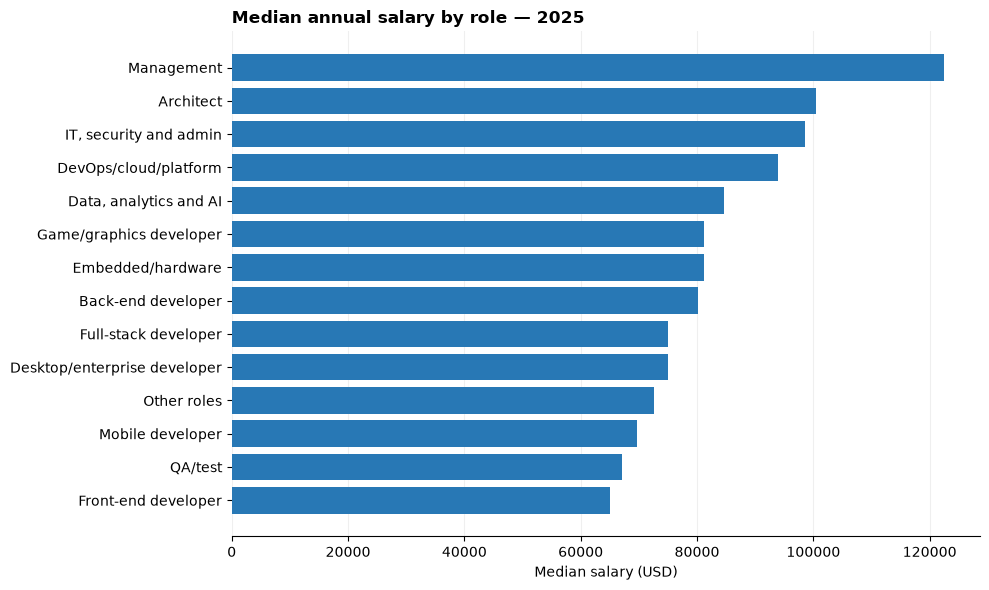

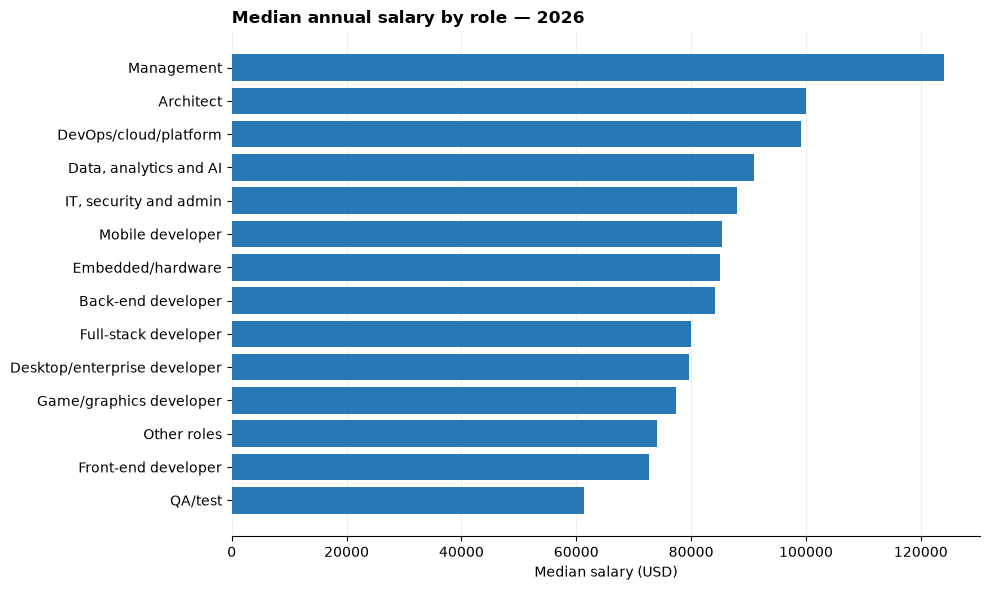

In [9]:
role_salary = pd.concat([
    df.loc[df.in_model.eq(1)].assign(year=year).groupby(["year", "role_group"]).salary_usd
      .agg(respondents="count", median_salary="median", average_salary="mean").reset_index()
    for year, df in [(2025, df_2025), (2026, df_2026)]], ignore_index=True)
display(role_salary.sort_values(["year", "median_salary"], ascending=[True, False]).head(20))
role_salary.to_csv(OUT / "role_salary_summary.csv", index=False)

for year in [2025, 2026]:
    data = role_salary[role_salary.year.eq(year)].sort_values("median_salary")
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(data.role_group, data.median_salary, color="#2878B5")
    ax.set_title(f"Median annual salary by role — {year}", loc="left", weight="bold")
    ax.set_xlabel("Median salary (USD)"); ax.grid(axis="x", alpha=.2); ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    fig.tight_layout(); fig.savefig(OUT / f"median_salary_by_role_{year}.png", dpi=160, bbox_inches="tight")
    plt.show()

## 9. Descriptive analytics: developer salaries by organization size and work setting

These views summarize average salary for employed developers by their reported organization size and work setting. The respondent count is shown with each bar so small cohorts can be interpreted cautiously.

The industry comparison below extends these descriptive summaries using the harmonized company-industry field.


,respondents,average_salary,median_salary
org_size,,,
"10,000 or more employees",2454,124768.662592,104000.0
"5,000 to 9,999 employees",791,107664.271808,89853.0
"1,000 to 4,999 employees",2103,102833.346172,88000.0
500 to 999 employees,1283,96356.293843,82950.0
100 to 499 employees,3325,93702.284812,81761.0
20 to 99 employees,3587,81375.020072,71499.0
Less than 20 employees,2529,71375.052590,60757.0
"Just me - I am a freelancer, sole proprietor, etc.",69,65187.043478,36479.0


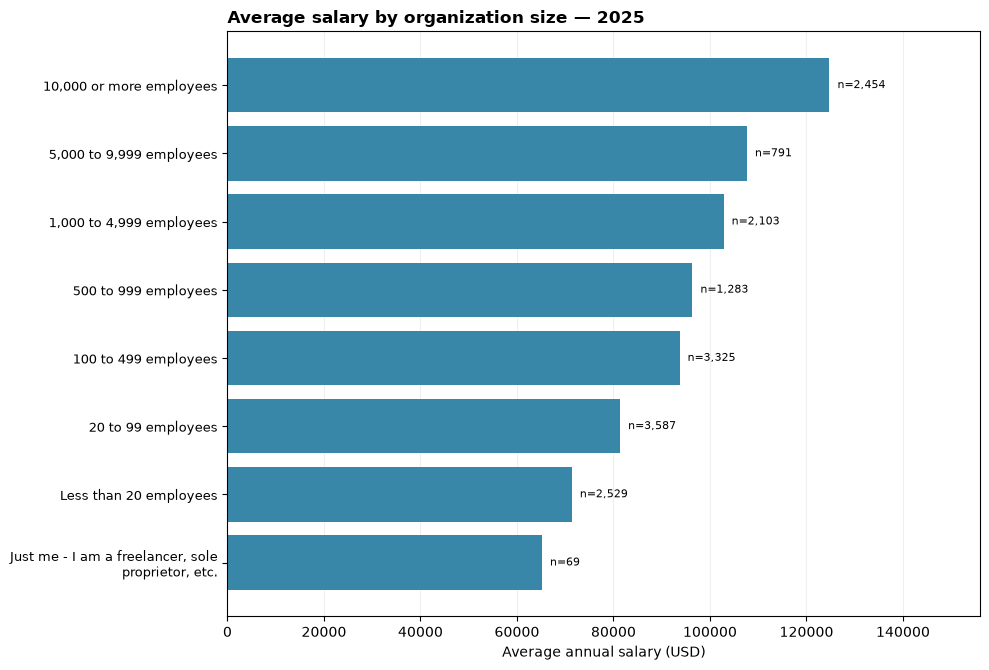

,respondents,average_salary,median_salary
work_setting,,,
Remote,5556,108699.283117,94781.0
"Hybrid (some in-person, leans heavy to flexibility)",3069,91743.217986,81368.0
"Hybrid (some remote, leans heavy to in-person)",3322,90940.388621,75410.0
"Your choice (very flexible, you can come in when you want or just as needed)",2080,89417.277404,79215.0
In-person,2235,71013.177181,51096.0


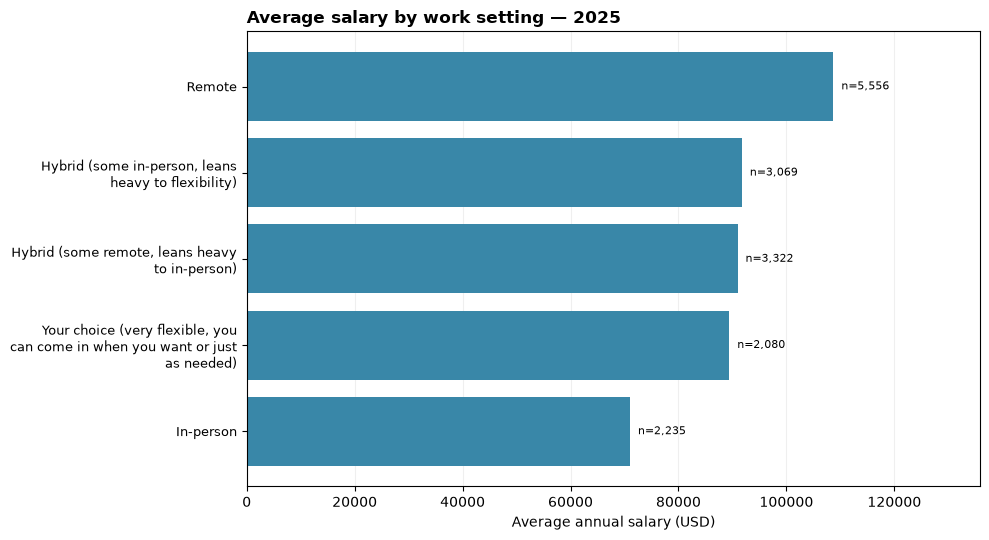

,respondents,average_salary,median_salary
org_size,,,
"10,000 or more employees",1464,127237.260246,108042.0
"5,000 to 9,999 employees",478,114007.949791,92878.0
"1,000 to 4,999 employees",1228,105202.410423,87571.0
500 to 999 employees,636,99298.523585,86540.5
100 to 499 employees,1772,95635.094808,85296.0
20 to 99 employees,1772,88035.556998,77619.5
"Just me - I am a freelancer, sole proprietor, etc.",30,78607.566667,32619.5
Less than 20 employees,1291,77223.349342,65394.0


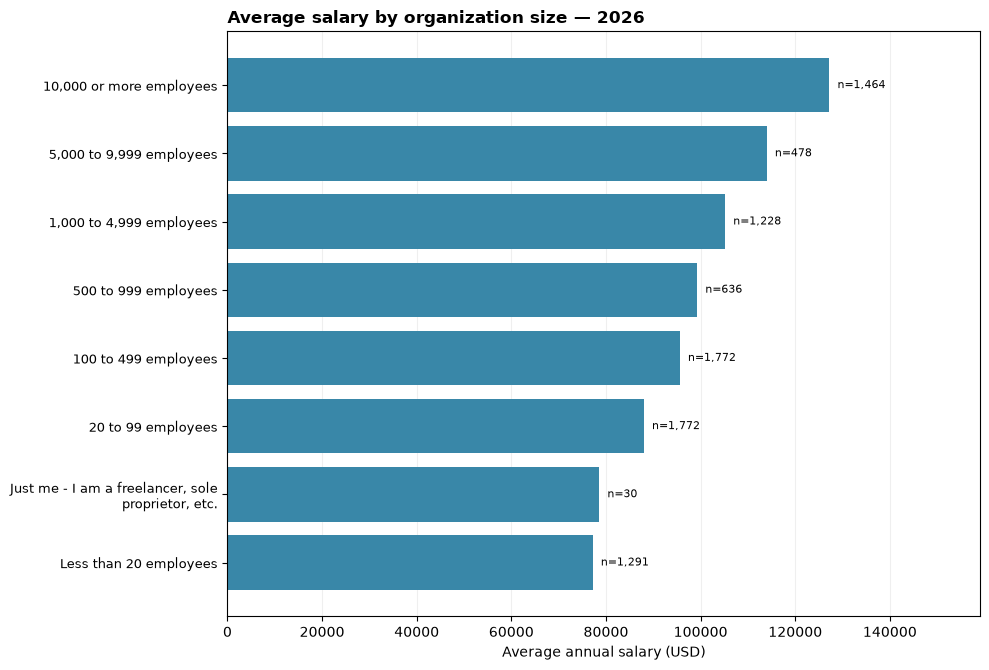

,respondents,average_salary,median_salary
work_setting,,,
Remote,2869,116074.938655,102355.0
"Hybrid (some remote, leans heavy to in-person)",1973,95114.154587,79798.0
"Hybrid (some in-person, leans heavy to flexibility)",1615,93533.453870,83640.0
"Your choice (very flexible, you can come in when you want or just as needed)",1073,93102.246039,82458.0
In-person,1250,78735.705600,61413.0


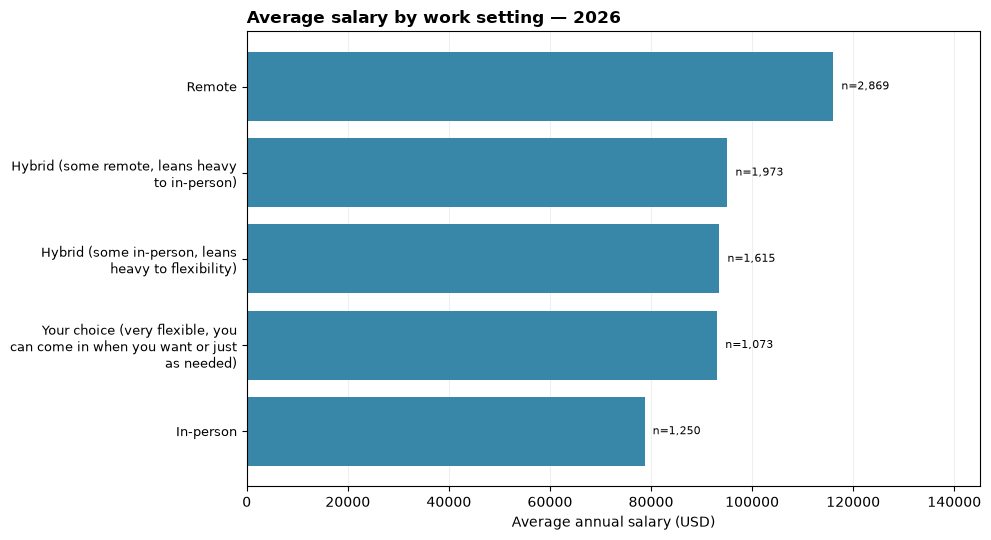

In [10]:
def plot_group_salary(df, year, group, title, filename):
    data = (df.loc[df.in_model.eq(1)].groupby(group).salary_usd
            .agg(respondents="count", average_salary="mean", median_salary="median")
            .sort_values("average_salary"))
    display(data.sort_values("average_salary", ascending=False))
    data.to_csv(OUT / filename)
    fig, ax = plt.subplots(figsize=(10, max(5.5, .85 * len(data))))
    labels = [textwrap.fill(str(label), width=34, break_long_words=False) for label in data.index]
    bars = ax.barh(np.arange(len(data)), data.average_salary, color="#3987a8")
    ax.set_yticks(np.arange(len(data)), labels=labels)
    ax.tick_params(axis="y", labelsize=9)
    ax.set_title(f"{title} — {year}", loc="left", weight="bold")
    ax.set_xlabel("Average annual salary (USD)"); ax.grid(axis="x", alpha=.2); ax.set_axisbelow(True)
    ax.set_xlim(0, data.average_salary.max() * 1.25)
    for bar, n in zip(bars, data.respondents):
        ax.text(bar.get_width(), bar.get_y()+bar.get_height()/2, f"  n={n:,}", va="center", fontsize=8)
    fig.tight_layout(); fig.savefig(OUT / f"{filename.replace('.csv','.png')}", dpi=160, bbox_inches="tight")
    plt.show()

for year, frame in [(2025, df_2025), (2026, df_2026)]:
    plot_group_salary(frame, year, "org_size", "Average salary by organization size", f"org_size_salary_{year}.csv")
    plot_group_salary(frame, year, "work_setting", "Average salary by work setting", f"work_setting_salary_{year}.csv")

### Industry salary patterns in the United States

This analysis focuses on the United States to avoid sparse country-level groups. It selects the three most-reported named industries among eligible respondents across 2025 and 2026, excluding blank and “Other/unspecified” responses. It compares median annual salary across professional-experience bands (0–4, 5–8, 9–12, 13–16, and 17+ years). Records with missing experience are excluded; chart points are shown only for groups with at least 20 respondents. The output table retains all available counts.

Top three US industries, ranked by eligible respondent count across both years:


,industry,respondents
0,Software development,1845
1,Healthcare,462
2,Government,412


US median salary by industry and experience band:


,year,industry,experience_band,respondents,median_salary
0,2025,Government,0-4 years,28,91150.0
1,2025,Government,5-8 years,49,116000.0
2,2025,Government,9-12 years,35,145000.0
3,2025,Government,13-16 years,30,135500.0
4,2025,Government,17+ years,104,150000.0
5,2025,Healthcare,0-4 years,33,100000.0
6,2025,Healthcare,5-8 years,49,123000.0
7,2025,Healthcare,9-12 years,53,155800.0
8,2025,Healthcare,13-16 years,33,175000.0
9,2025,Healthcare,17+ years,120,170000.0


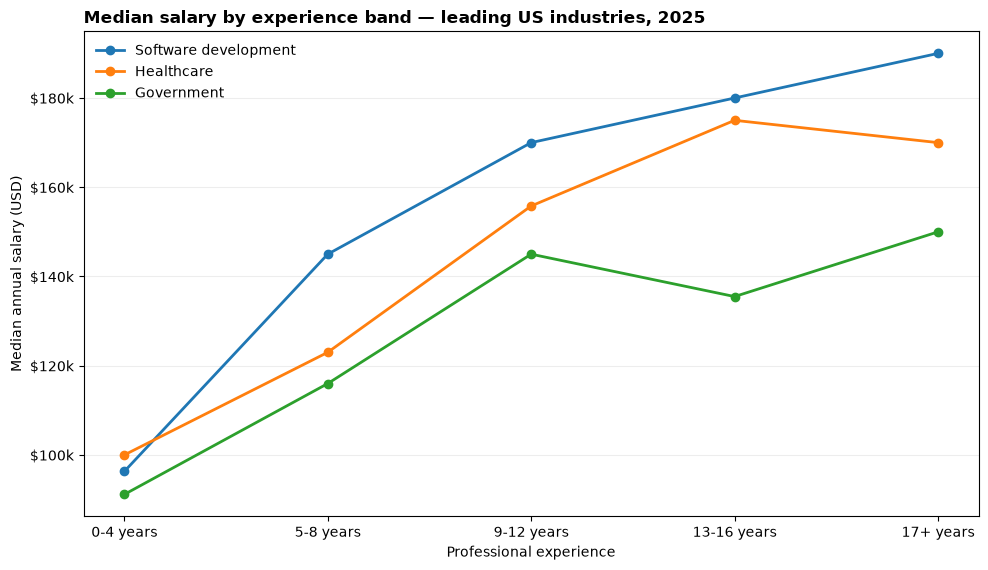

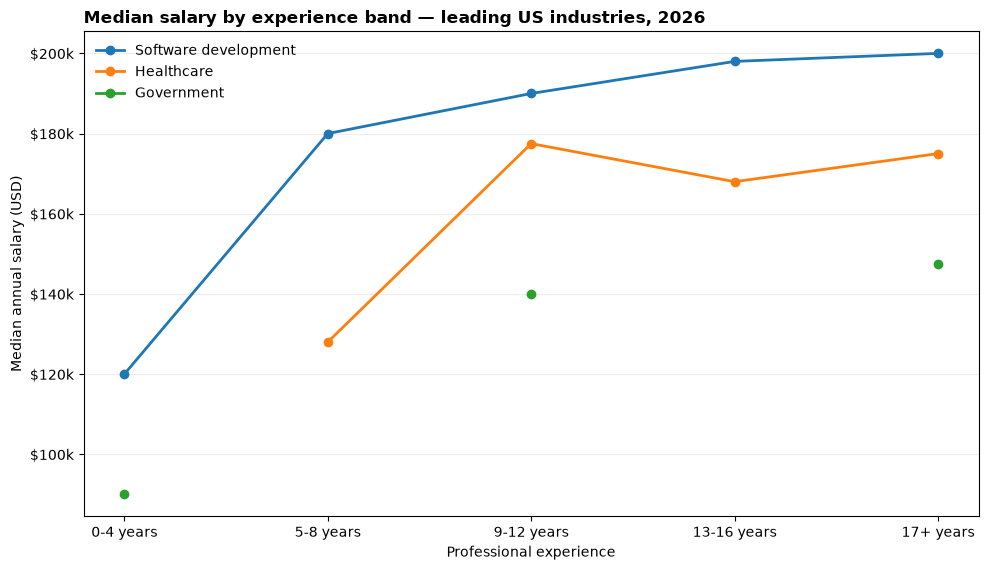

In [11]:
EXPERIENCE_BANDS = ["0-4 years", "5-8 years", "9-12 years", "13-16 years", "17+ years"]
EXPERIENCE_EDGES = [0, 5, 9, 13, 17, float("inf")]
US_COUNTRY = "United States of America"

# Select leading US industries using respondent counts pooled across both survey years.
us_eligible = pd.concat([
    frame.loc[frame.in_model.eq(1) & frame.country.eq(US_COUNTRY), ["industry"]]
    for frame in (df_2025, df_2026)
], ignore_index=True)
us_industry_counts = (us_eligible.loc[
    us_eligible.industry.ne("Not stated") & us_eligible.industry.ne("Other/unspecified")
].industry.value_counts().rename_axis("industry").reset_index(name="respondents"))
top_us_industries = us_industry_counts.head(3).copy()

print("Top three US industries, ranked by eligible respondent count across both years:")
display(top_us_industries)
top_us_industries.to_csv(OUT / "top_us_industries.csv", index=False)

experience_summary = []
for year, frame in [(2025, df_2025), (2026, df_2026)]:
    selected = frame.loc[
        frame.in_model.eq(1) & frame.country.eq(US_COUNTRY) &
        frame.industry.isin(top_us_industries.industry) &
        frame.work_exp_blank.eq(0) & frame.work_exp.notna()
    ].copy()
    selected["experience_band"] = pd.cut(
        selected.work_exp, bins=EXPERIENCE_EDGES, labels=EXPERIENCE_BANDS,
        right=False, include_lowest=True)
    summary = (selected.dropna(subset=["experience_band"])
        .groupby(["year", "industry", "experience_band"], observed=True)
        .salary_usd.agg(respondents="count", median_salary="median")
        .reset_index())
    experience_summary.append(summary)

us_industry_experience_salary = pd.concat(experience_summary, ignore_index=True)
us_industry_experience_salary.to_csv(OUT / "us_industry_salary_by_experience.csv", index=False)
print("US median salary by industry and experience band:")
display(us_industry_experience_salary.round(0))

for year in (2025, 2026):
    fig, ax = plt.subplots(figsize=(10, 5.8))
    for industry in top_us_industries.industry:
        part = us_industry_experience_salary.loc[
            us_industry_experience_salary.year.eq(year) &
            us_industry_experience_salary.industry.eq(industry)
        ].set_index("experience_band").reindex(EXPERIENCE_BANDS)
        values = part.median_salary.where(part.respondents.ge(20))
        ax.plot(EXPERIENCE_BANDS, values, marker="o", linewidth=2,
                label=textwrap.fill(industry, 34))
    ax.set_title(f"Median salary by experience band — leading US industries, {year}",
                 loc="left", weight="bold")
    ax.set_xlabel("Professional experience")
    ax.set_ylabel("Median annual salary (USD)")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: "$" + f"{value/1000:,.0f}k"))
    ax.grid(axis="y", alpha=.22)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, loc="best")
    fig.tight_layout()
    fig.savefig(OUT / f"us_industry_median_salary_by_experience_{year}.png",
                dpi=160, bbox_inches="tight")
    plt.show()


## 10. Predictive analytics: 2025 training and 2026 testing

The continuous-salary models predict annual salary in USD for the eligible professional developer cohort. The random forest settings below were selected by an earlier randomized search with three-fold cross-validation on 2025 data; routine runs use those fixed settings. The 2026 survey remains held for final evaluation.

For regression, we report MAE, RMSE, median absolute error, and R². The salary-band subsection separately evaluates classification metrics, since R² does not apply to band labels. Skill vocabularies are learned from 2025 and applied to 2026; unseen categories and tokens are safely ignored.

In [12]:
NUMERIC = ["work_exp", "years_code"]
CATEGORICAL = ["country", "age", "role_group", "education", "org_size", "work_setting"]
FEATURES = NUMERIC + CATEGORICAL + SKILL_FIELDS
train = df_2025.loc[df_2025.in_model.eq(1)].copy().reset_index(drop=True)
test = df_2026.loc[df_2026.in_model.eq(1)].copy().reset_index(drop=True)
X_train, y_train = train[FEATURES], train.salary_usd
X_test, y_test = test[FEATURES], test.salary_usd
print(f"Training rows (2025): {len(train):,}; test rows (2026): {len(test):,}")

def split_tokens(text):
    return [item.strip() for item in str(text).split(";") if item.strip()]

def make_pipeline(include_skills=True, params=None):
    transforms = [
        ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUMERIC),
        ("categorical", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                  ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CATEGORICAL)]
    if include_skills:
        for col in SKILL_FIELDS:
            transforms.append((f"{col}_tokens", CountVectorizer(tokenizer=split_tokens,
                token_pattern=None, lowercase=False, binary=True, min_df=25), col))
    preprocessor = ColumnTransformer(transforms, remainder="drop")
    settings = {"n_estimators":120, "max_depth":None, "min_samples_split":20,
        "min_samples_leaf":3, "max_features":1.0, "max_samples":0.9,
        "random_state":42, "n_jobs":-1}
    if params:
        settings.update(params)
    forest = RandomForestRegressor(**settings)
    log_target = TransformedTargetRegressor(regressor=forest, func=np.log1p,
        inverse_func=np.expm1, check_inverse=False)
    return Pipeline([("features", preprocessor), ("model", log_target)])

RF_PARAMS = {"n_estimators":120, "max_depth":None, "min_samples_split":20,
    "min_samples_leaf":3, "max_features":1.0, "max_samples":0.9,
    "random_state":42, "n_jobs":-1}
best_model = make_pipeline(True, RF_PARAMS)
best_model.fit(X_train, y_train)
predictions = best_model.predict(X_test)
print("Random forest fit completed using previously selected fixed hyperparameters:", RF_PARAMS)

Training rows (2025): 16,337; test rows (2026): 8,784


Random forest fit completed using previously selected fixed hyperparameters: {'n_estimators': 120, 'max_depth': None, 'min_samples_split': 20, 'min_samples_leaf': 3, 'max_features': 1.0, 'max_samples': 0.9, 'random_state': 42, 'n_jobs': -1}


In [13]:
linear_model = Pipeline([
    ("features", make_pipeline(True).named_steps["features"]),
    ("model", TransformedTargetRegressor(regressor=LinearRegression(),
        func=np.log1p, inverse_func=np.expm1, check_inverse=False))])
linear_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_test)
print("Linear regression fitted with the same features and log-salary target transformation.")

Linear regression fitted with the same features and log-salary target transformation.


## 11. Compare linear regression and random forest

Both models use the same 2025 training rows, 2026 test rows, feature columns, preprocessing, and log-salary target transformation. The random forest uses fixed settings selected during earlier 2025 cross-validation; this run does not repeat the search. Linear regression is fit directly on 2025. The metrics compare their 2026 predictions; lower error and higher R² indicate better results.

,model,MAE_USD,RMSE_USD,Median_AE_USD,R_squared
0,Tuned random forest,29970.250,48214.083,19179.104,0.555
1,Linear regression,29903.853,48437.797,18299.802,0.551


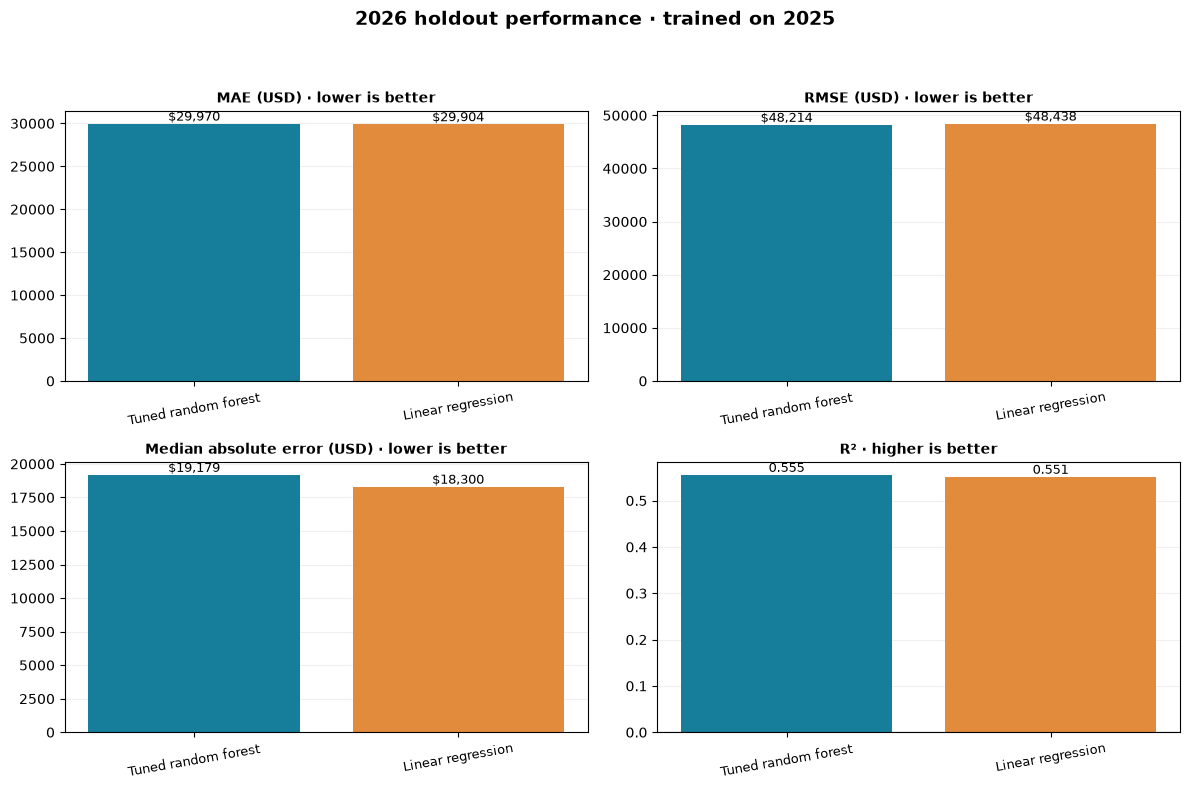

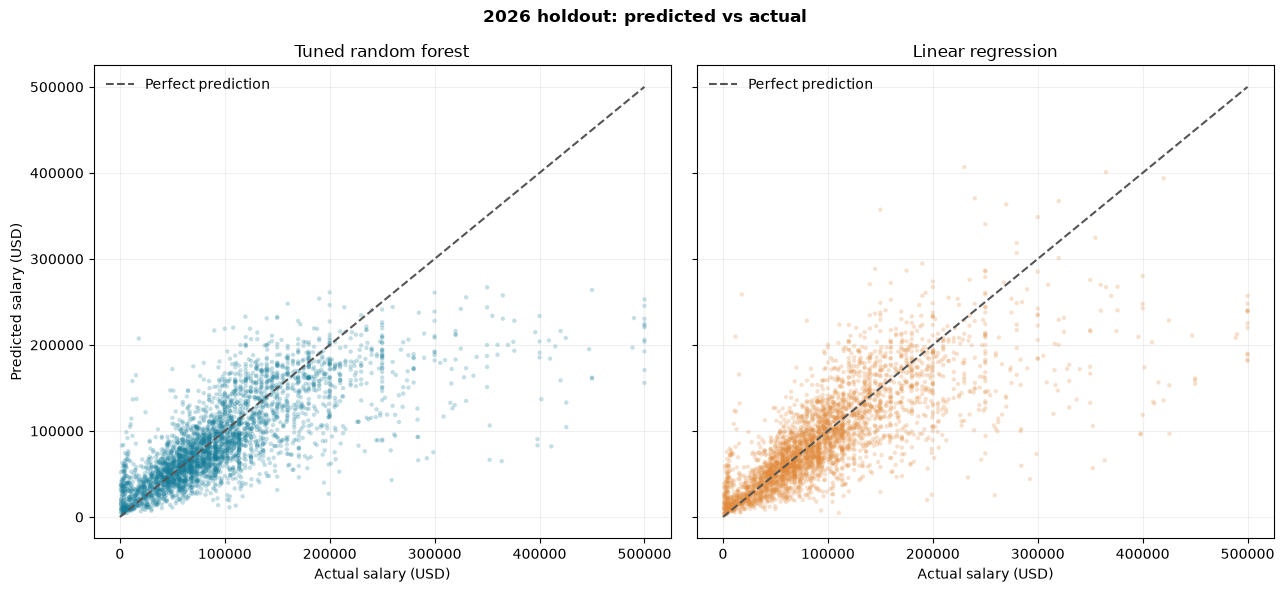

In [14]:
def regression_metrics(actual, predicted):
    return {"MAE_USD":mean_absolute_error(actual, predicted),
        "RMSE_USD":np.sqrt(mean_squared_error(actual, predicted)),
        "Median_AE_USD":median_absolute_error(actual, predicted),
        "R_squared":r2_score(actual, predicted)}

rf_metrics = regression_metrics(y_test, predictions)
linear_metrics = regression_metrics(y_test, linear_predictions)
comparison = pd.DataFrame([
    {"model":"Tuned random forest", **rf_metrics},
    {"model":"Linear regression", **linear_metrics}])
display(comparison.round(3))
comparison.to_csv(OUT / "predictive_model_metrics.csv", index=False)
pd.DataFrame({"actual_salary_usd":y_test, "predicted_random_forest_usd":predictions,
              "predicted_linear_regression_usd":linear_predictions}).to_csv(
    OUT / "predictions_2026.csv", index=False)
(OUT / "best_model_parameters.json").write_text(json.dumps(RF_PARAMS, indent=2, default=str))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
specs = [("MAE_USD", "MAE (USD) · lower is better", True),
         ("RMSE_USD", "RMSE (USD) · lower is better", True),
         ("Median_AE_USD", "Median absolute error (USD) · lower is better", True),
         ("R_squared", "R² · higher is better", False)]
colors = ["#167d9a", "#e28b3c"]
for ax, (metric, title, money) in zip(axes.flat, specs):
    bars = ax.bar(comparison.model, comparison[metric], color=colors)
    ax.set_title(title, weight="bold", fontsize=10)
    ax.tick_params(axis="x", rotation=10, labelsize=9)
    ax.grid(axis="y", alpha=.2); ax.set_axisbelow(True)
    if metric == "R_squared": ax.axhline(0, color="#555", linewidth=.8)
    for bar, value in zip(bars, comparison[metric]):
        label = "$" + format(value, ",.0f") if money else format(value, ".3f")
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height(), label,
                ha="center", va="bottom", fontsize=9)
fig.suptitle("2026 holdout performance · trained on 2025", fontsize=14, weight="bold")
fig.tight_layout(rect=[0, 0, 1, .94]); fig.savefig(OUT / "model_metrics_comparison.png", dpi=170, bbox_inches="tight")
plt.show()

rng = np.random.default_rng(42)
sample_idx = rng.choice(len(y_test), min(3500, len(y_test)), replace=False)
actual_sample = y_test.iloc[sample_idx].to_numpy()
rf_sample = predictions[sample_idx]
linear_sample = linear_predictions[sample_idx]
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True, sharey=True)
limit = max(actual_sample.max(), rf_sample.max(), linear_sample.max())
for ax, sample, name, color in zip(axes, [rf_sample, linear_sample],
        ["Tuned random forest", "Linear regression"], colors):
    ax.scatter(actual_sample, sample, s=10, alpha=.25, color=color, edgecolors="none")
    ax.plot([0, limit], [0, limit], "--", color="#555", label="Perfect prediction")
    ax.set(title=name, xlabel="Actual salary (USD)"); ax.grid(alpha=.2); ax.legend(frameon=False)
axes[0].set_ylabel("Predicted salary (USD)")
fig.suptitle("2026 holdout: predicted vs actual", weight="bold"); fig.tight_layout()
fig.savefig(OUT / "predicted_vs_actual.png", dpi=170, bbox_inches="tight"); plt.show()

### Salary-band classification comparison

To test whether predicting ranges is more useful than predicting exact salary, this subsection defines four salary bands from the 25th, 50th, and 75th percentiles of eligible 2025 training salaries. Those cutoffs are fixed and applied to the 2026 holdout. It compares the existing random forest and linear regression predictions after mapping them to bands against direct random forest and logistic regression classifiers. All approaches use the same 2025/2026 split and predictors. Classification results use accuracy, balanced accuracy, macro precision/recall/F1, and confusion matrices; R² applies only to the continuous-salary models.

,cutoff,salary_usd
0,Q1 / Band 1 upper bound,46406.0
1,Q2 / Band 2 upper bound,80984.0
2,Q3 / Band 3 upper bound,125000.0


Band definitions come only from 2025 training salaries; the same thresholds are used on 2026.


,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
3,Logistic regression classifier,0.624,0.628,0.627,0.628,0.627,0.623
2,Random forest classifier,0.622,0.625,0.627,0.625,0.626,0.623
1,Linear regression → band,0.616,0.622,0.622,0.622,0.621,0.617
0,Random forest regression → band,0.597,0.601,0.607,0.601,0.602,0.599


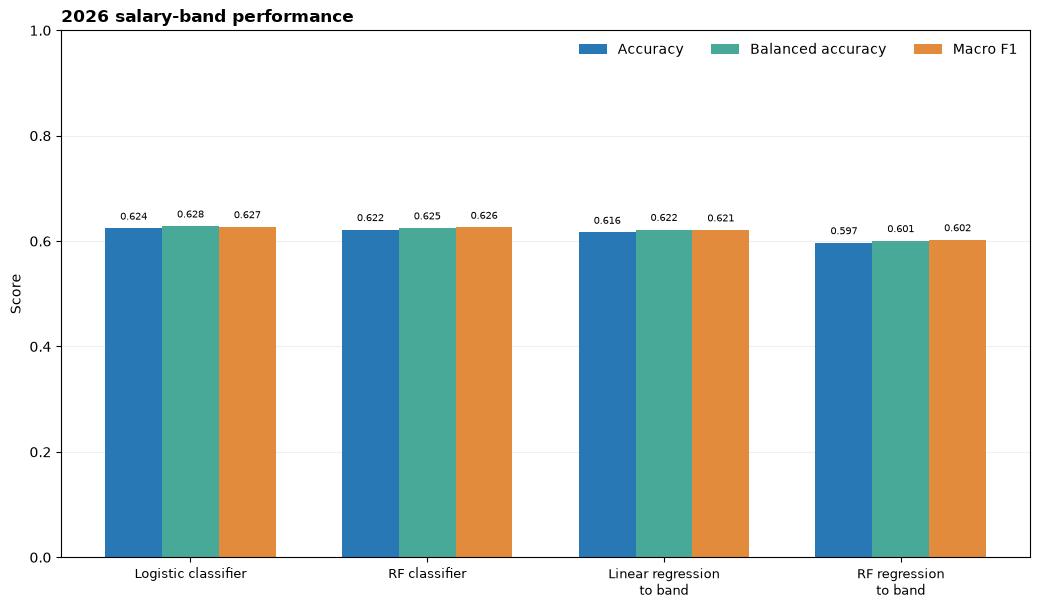

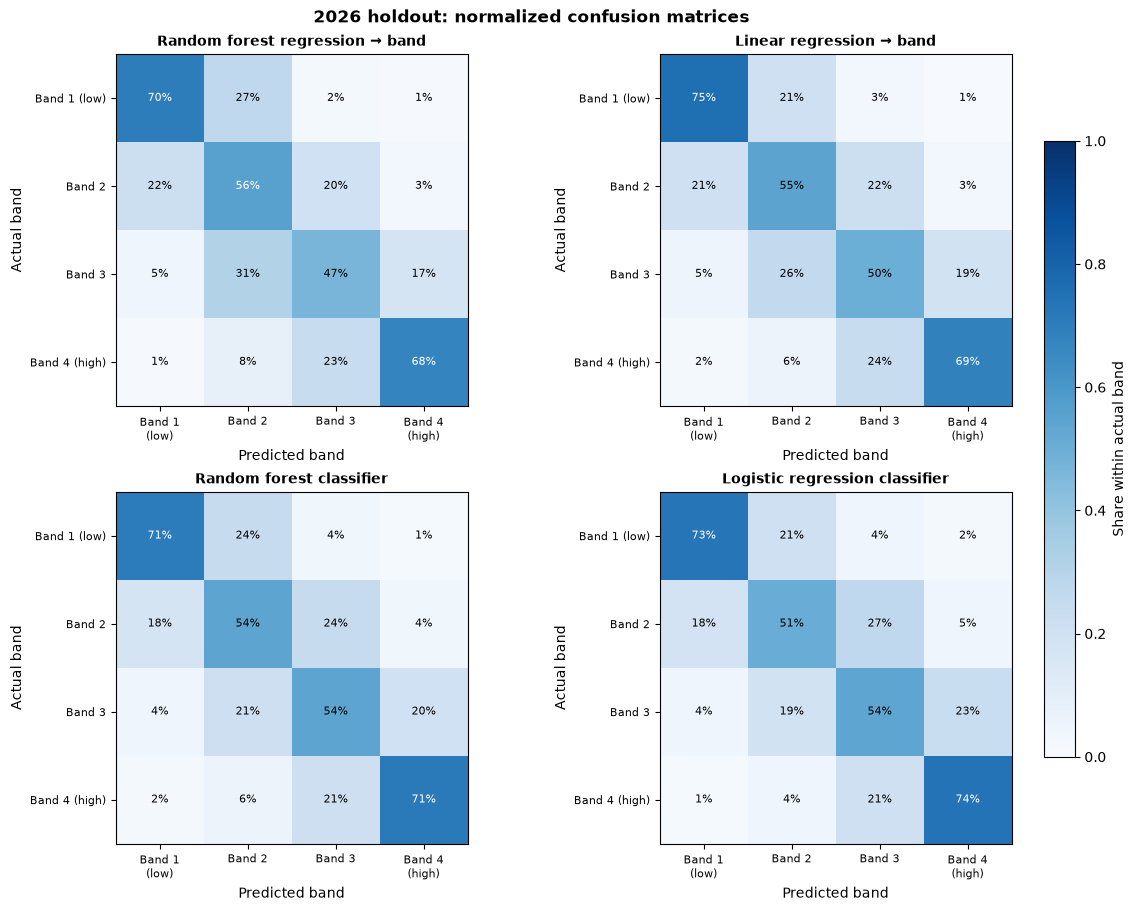

In [15]:
BAND_LABELS = ["Band 1 (lowest)", "Band 2", "Band 3", "Band 4 (highest)"]
band_cutoffs = y_train.quantile([0.25, 0.50, 0.75]).to_numpy()
if len(np.unique(band_cutoffs)) != 3:
    raise ValueError("Salary quartile cutoffs are not distinct; choose explicit salary thresholds.")
salary_bins = [-np.inf, *band_cutoffs, np.inf]
def to_salary_band(values):
    return pd.cut(pd.Series(np.asarray(values)), bins=salary_bins, labels=False,
                  include_lowest=True).astype("int64").to_numpy()

y_train_band = to_salary_band(y_train)
y_test_band = to_salary_band(y_test)
cutoff_table = pd.DataFrame({"cutoff":"Q1 / Band 1 upper bound", "salary_usd":[band_cutoffs[0]]})
cutoff_table = pd.concat([cutoff_table, pd.DataFrame({
    "cutoff":["Q2 / Band 2 upper bound", "Q3 / Band 3 upper bound"],
    "salary_usd":band_cutoffs[1:]
})], ignore_index=True)
display(cutoff_table.round(0))
cutoff_table.to_csv(OUT / "salary_band_cutpoints.csv", index=False)
print("Band definitions come only from 2025 training salaries; the same thresholds are used on 2026.")

# Map the two existing regression models' predicted USD values into the fixed salary bands.
band_predictions = {
    "Random forest regression → band": to_salary_band(predictions),
    "Linear regression → band": to_salary_band(linear_predictions)
}

def make_classifier_pipeline(estimator):
    feature_prep = make_pipeline(True).named_steps["features"]
    return Pipeline([("features", feature_prep), ("model", estimator)])

rf_classifier = make_classifier_pipeline(RandomForestClassifier(**RF_PARAMS))
rf_classifier.fit(X_train, y_train_band)
band_predictions["Random forest classifier"] = rf_classifier.predict(X_test)

logistic_classifier = make_classifier_pipeline(LogisticRegression(max_iter=2000, solver="lbfgs"))
logistic_classifier.fit(X_train, y_train_band)
band_predictions["Logistic regression classifier"] = logistic_classifier.predict(X_test)

class_ids = [0, 1, 2, 3]
metric_rows = []
class_rows = []
confusion_rows = []
for model_name, predicted_band in band_predictions.items():
    precision, recall, f1, support = precision_recall_fscore_support(
        y_test_band, predicted_band, labels=class_ids, average=None, zero_division=0)
    metric_rows.append({
        "model":model_name,
        "accuracy":accuracy_score(y_test_band, predicted_band),
        "balanced_accuracy":balanced_accuracy_score(y_test_band, predicted_band),
        "macro_precision":precision.mean(), "macro_recall":recall.mean(),
        "macro_f1":f1.mean(), "weighted_f1":precision_recall_fscore_support(
            y_test_band, predicted_band, labels=class_ids, average="weighted", zero_division=0)[2]
    })
    for class_id, p, r, score, n in zip(class_ids, precision, recall, f1, support):
        class_rows.append({"model":model_name, "salary_band":BAND_LABELS[class_id],
                           "precision":p, "recall":r, "f1":score, "support":n})
    cm = confusion_matrix(y_test_band, predicted_band, labels=class_ids)
    cm_norm = confusion_matrix(y_test_band, predicted_band, labels=class_ids, normalize="true")
    for actual_id in class_ids:
        for predicted_id in class_ids:
            confusion_rows.append({"model":model_name,
                "actual_band":BAND_LABELS[actual_id], "predicted_band":BAND_LABELS[predicted_id],
                "respondents":cm[actual_id, predicted_id],
                "row_normalized_share":cm_norm[actual_id, predicted_id]})

band_metrics = pd.DataFrame(metric_rows).sort_values("macro_f1", ascending=False)
display(band_metrics.round(3))
band_metrics.to_csv(OUT / "salary_band_classification_metrics.csv", index=False)
pd.DataFrame(class_rows).to_csv(OUT / "salary_band_class_metrics.csv", index=False)
pd.DataFrame(confusion_rows).to_csv(OUT / "salary_band_confusion_matrices.csv", index=False)
band_labels_by_id = dict(enumerate(BAND_LABELS))
pd.DataFrame({
    "actual_salary_usd":y_test.to_numpy(),
    "actual_band":[band_labels_by_id[x] for x in y_test_band],
    **{f"predicted_{name}":[band_labels_by_id[int(x)] for x in values]
       for name, values in band_predictions.items()}
}).to_csv(OUT / "salary_band_predictions_2026.csv", index=False)

fig, ax = plt.subplots(figsize=(10.5, 6.2))
x = np.arange(len(band_metrics)); width = .24
for offset, metric, label, color in [
    (-width, "accuracy", "Accuracy", "#2878B5"),
    (0, "balanced_accuracy", "Balanced accuracy", "#48A999"),
    (width, "macro_f1", "Macro F1", "#E28B3C")
]:
    ax.bar(x + offset, band_metrics[metric], width, label=label, color=color)
short_label_map = {"Random forest regression → band":"RF regression\nto band", "Linear regression → band":"Linear regression\nto band", "Random forest classifier":"RF classifier", "Logistic regression classifier":"Logistic classifier"}
ax.set_xticks(x, [short_label_map[name] for name in band_metrics.model], fontsize=9)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("2026 salary-band performance", loc="left", weight="bold")
ax.grid(axis="y", alpha=.2); ax.set_axisbelow(True); ax.legend(frameon=False, ncols=3)
for offset, metric, label, color in [(-width, "accuracy", "Accuracy", "#2878B5"), (0, "balanced_accuracy", "Balanced accuracy", "#48A999"), (width, "macro_f1", "Macro F1", "#E28B3C")]:
    for bar, value in zip(ax.containers[["accuracy", "balanced_accuracy", "macro_f1"].index(metric)], band_metrics[metric]):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+.012, f"{value:.3f}", ha="center", va="bottom", fontsize=7)
fig.tight_layout(); fig.savefig(OUT / "salary_band_metrics.png", dpi=170, bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 9), layout="constrained")
for ax, (model_name, predicted_band) in zip(axes.flat, band_predictions.items()):
    matrix = confusion_matrix(y_test_band, predicted_band, labels=class_ids, normalize="true")
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(model_name, fontsize=10, weight="bold")
    ax.set_xticks(class_ids, ["Band 1\n(low)", "Band 2", "Band 3", "Band 4\n(high)"], fontsize=8)
    ax.set_yticks(class_ids, ["Band 1 (low)", "Band 2", "Band 3", "Band 4 (high)"], fontsize=8)
    ax.set_xlabel("Predicted band"); ax.set_ylabel("Actual band")
    for row in class_ids:
        for col in class_ids:
            ax.text(col, row, f"{matrix[row, col]:.0%}", ha="center", va="center",
                    color="white" if matrix[row, col] > .55 else "black", fontsize=8)
colorbar = fig.colorbar(image, ax=axes.ravel().tolist(), shrink=.78, pad=.03)
colorbar.set_label("Share within actual band")
fig.suptitle("2026 holdout: normalized confusion matrices", weight="bold")
fig.savefig(OUT / "salary_band_confusion_matrices.png", dpi=170, bbox_inches="tight")
plt.show()


## 12. Random forest skill scenario analysis

For a small set of candidate skills, this section toggles one skill on for 2026 profiles who did not report it, then compares random forest predictions while holding the other answers fixed. This describes model sensitivity only; it does not estimate causal salary gains from learning a skill.

,skill,profiles_compared,mean_prediction_change_usd,median_prediction_change_usd,share_with_increase_pct
1,Azure,7285,-517.12,-62.71,40.08
6,java,7108,-94.35,-106.71,41.05
3,docker,5450,1213.63,516.92,71.83
2,GCP,7557,1334.83,377.99,66.31
0,AWS,6406,1804.10,900.32,81.49
4,kubernetes,7230,2931.64,1990.18,86.40
5,terraform,7657,3835.41,2777.71,89.46


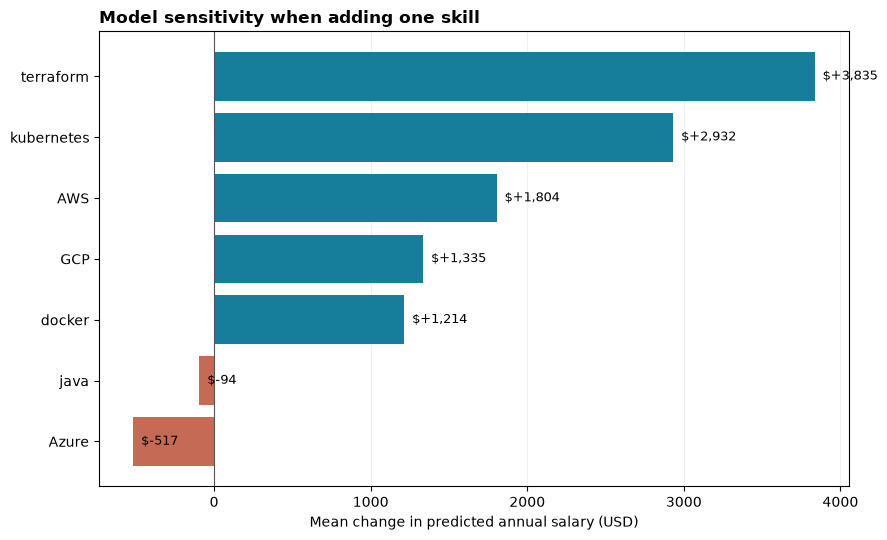

In [16]:
CANDIDATE_SKILLS = {
    "AWS": ("cloud_list", "amazon web services (aws)"),
    "Azure": ("cloud_list", "microsoft azure"),
    "GCP": ("cloud_list", "google cloud"),
    "docker": ("cloud_list", "docker"),
    "kubernetes": ("cloud_list", "kubernetes"),
    "terraform": ("cloud_list", "terraform"),
    "java": ("lang_list", "java"),
}
scenario_rows = []
for skill, (column, token) in CANDIDATE_SKILLS.items():
    is_present = test[column].map(lambda cell: token in {t.lower() for t in split_tokens(cell)})
    profiles = X_test.loc[~is_present].copy()
    if profiles.empty:
        continue
    changed = profiles.copy()
    changed[column] = changed[column].map(lambda cell: (cell + ";" if cell else "") + token)
    delta = best_model.predict(changed) - best_model.predict(profiles)
    scenario_rows.append({"skill":skill, "profiles_compared":len(delta),
        "mean_prediction_change_usd":float(np.mean(delta)),
        "median_prediction_change_usd":float(np.median(delta)),
        "share_with_increase_pct":float(np.mean(delta > 0) * 100)})
scenario = pd.DataFrame(scenario_rows).sort_values("mean_prediction_change_usd")
display(scenario.round(2))
scenario.to_csv(OUT / "candidate_skill_scenarios.csv", index=False)
if not scenario.empty:
    colors = ["#c56b55" if x < 0 else "#167d9a" for x in scenario.mean_prediction_change_usd]
    fig, ax = plt.subplots(figsize=(9, 5.5))
    bars = ax.barh(scenario.skill, scenario.mean_prediction_change_usd, color=colors)
    ax.axvline(0, color="#555", linewidth=.8)
    for bar, value in zip(bars, scenario.mean_prediction_change_usd):
        ax.text(value, bar.get_y()+bar.get_height()/2, f"  ${value:+,.0f}", va="center", fontsize=9)
    ax.set_title("Model sensitivity when adding one skill", loc="left", weight="bold")
    ax.set_xlabel("Mean change in predicted annual salary (USD)"); ax.grid(axis="x", alpha=.2); ax.set_axisbelow(True)
    fig.tight_layout(); fig.savefig(OUT / "candidate_skill_scenarios.png", dpi=170, bbox_inches="tight")
    plt.show()


### 13. Prescriptive analytics: simulate a three-year skill and experience trajectory

This scenario starts from the static hypothetical profile. At the current experience level, it adds Java and Docker. At the end of year 1, it increases professional experience and coding years by one, then adds Kubernetes and Terraform. At the end of year 2, it increases both years by one, then adds AWS, GCP, and Azure. A final year-3 checkpoint increases both experience measures by one more while holding skills fixed. The table and graph show the predicted change at every skill addition and year checkpoint.

Each row reports the change from the previous checkpoint and the cumulative change from baseline for both models. This is a hypothetical pathway estimated from cross-sectional survey models; it is not evidence that these skills or experience increments cause the predicted salary change. Random Forest predictions can jump at experience thresholds because the model uses tree splits; large step changes should be interpreted cautiously.

Static hypothetical profile (all non-skill inputs and base skills held constant):


,country,age,role_group,work_exp_years,years_code,education,org_size,work_setting
0,India,25-34 years old,Back-end developer,5,8,Bachelor's,100 to 499 employees,Remote


,skill_family,existing_skills
0,lang_list,python;javascript;sql
1,db_list,postgresql;redis
2,web_list,react;node.js
3,ide_list,visual studio code;intellij idea
4,cloud_list,cloudflare


,step,checkpoint,event_type,skill_added,skills_added_cumulative,elapsed_years,work_exp_years,years_code,random_forest_predicted_salary_usd,random_forest_incremental_change_usd,random_forest_change_from_baseline_usd,linear_regression_predicted_salary_usd,linear_regression_incremental_change_usd,linear_regression_change_from_baseline_usd,average_incremental_prediction_change_usd,model_direction_agreement
0,0,Baseline,Baseline,,None,0,5,8,19569.82,0.00,0.00,22472.90,0.00,0.00,0.00,Baseline
1,1,Add java,skill,java,java,0,5,8,19891.61,321.79,321.79,21723.52,-749.38,-749.38,-213.79,Models disagree at this step
2,2,Add docker,skill,docker,java + docker,0,5,8,20026.01,134.40,456.18,22100.89,377.37,-372.01,255.88,Both predict no decrease at this step
3,3,Year 1 experience checkpoint,experience,,java + docker,1,6,9,31407.12,11381.12,11837.30,22727.57,626.68,254.67,6003.90,Both predict no decrease at this step
4,4,Add kubernetes,skill,kubernetes,java + docker + kubernetes,1,6,9,33453.18,2046.05,13883.36,23815.12,1087.55,1342.22,1566.80,Both predict no decrease at this step
5,5,Add terraform,skill,terraform,java + docker + kubernetes + terraform,1,6,9,33360.14,-93.04,13790.32,24100.29,285.17,1627.39,96.07,Models disagree at this step
6,6,Year 2 experience checkpoint,experience,,java + docker + kubernetes + terraform,2,7,10,36985.71,3625.57,17415.89,24783.66,683.37,2310.76,2154.47,Both predict no decrease at this step
7,7,Add AWS,skill,AWS,java + docker + kubernetes + terraform + AWS,2,7,10,37571.74,586.03,18001.92,25892.23,1108.57,3419.34,847.30,Both predict no decrease at this step
8,8,Add GCP,skill,GCP,java + docker + kubernetes + terraform + AWS +...,2,7,10,37571.74,0.00,18001.92,26844.58,952.35,4371.68,476.17,Both predict no decrease at this step
9,9,Add Azure,skill,Azure,java + docker + kubernetes + terraform + AWS +...,2,7,10,37571.74,0.00,18001.92,25975.37,-869.21,3502.47,-434.61,Both predict no increase at this step


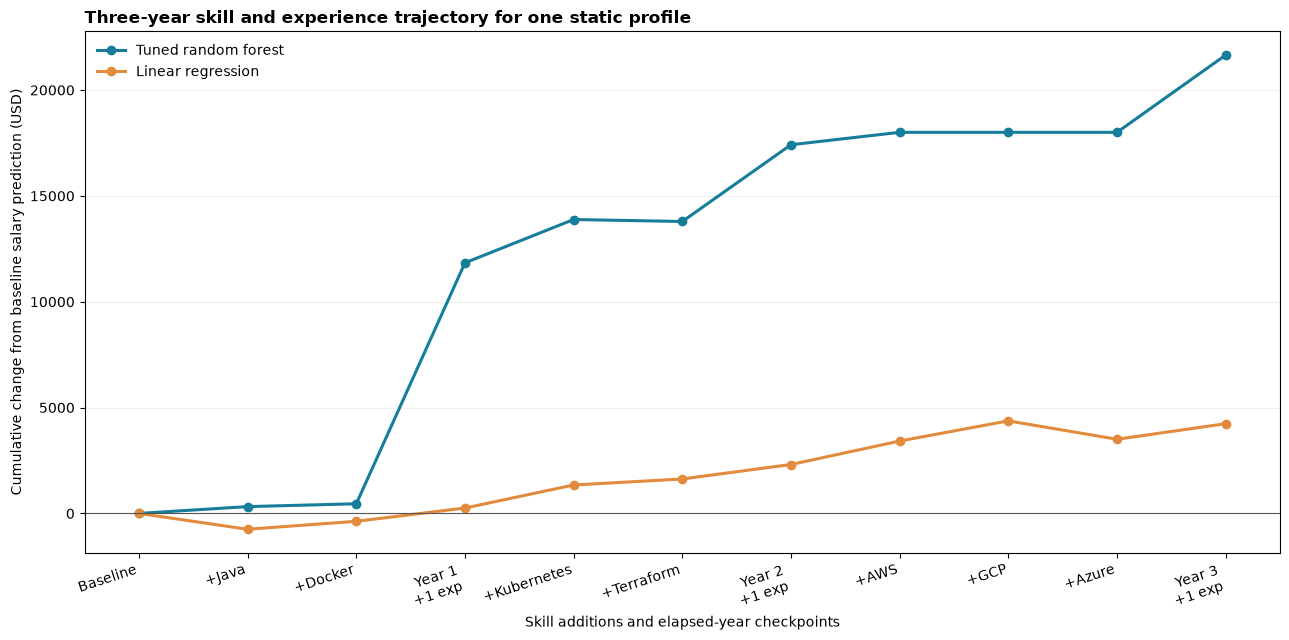

After three years, predicted change from baseline: Random Forest $21,653; Linear Regression $4,239


In [17]:
# Static hypothetical profile. These values are explicit model inputs, not a sampled respondent.
# Use category labels found in the training data and leave candidate skills out of the base profile.
static_profile = {
    "work_exp": 5,
    "years_code": 8,
    "country": "India",
    "age": "25-34 years old",
    "role_group": "Back-end developer",
    "education": "Bachelor's",
    "org_size": "100 to 499 employees",
    "work_setting": "Remote",
    "lang_list": "python;javascript;sql",
    "db_list": "postgresql;redis",
    "web_list": "react;node.js",
    "ide_list": "visual studio code;intellij idea",
    "cloud_list": "cloudflare",
}
profile = pd.DataFrame([static_profile], columns=FEATURES)
profile_row = pd.Series(static_profile)

profile_summary = pd.DataFrame([{"country":profile_row.country, "age":profile_row.age,
    "role_group":profile_row.role_group, "work_exp_years":profile_row.work_exp,
    "years_code":profile_row.years_code, "education":profile_row.education,
    "org_size":profile_row.org_size, "work_setting":profile_row.work_setting}])
print("Static hypothetical profile (all non-skill inputs and base skills held constant):")
display(profile_summary)
display(pd.DataFrame({"skill_family":SKILL_FIELDS,
    "existing_skills":[profile.iloc[0][field] for field in SKILL_FIELDS]}))

NEW_SKILLS = {
    "java": ("lang_list", "java"),
    "docker": ("cloud_list", "docker"),
    "kubernetes": ("cloud_list", "kubernetes"),
    "terraform": ("cloud_list", "terraform"),
    "AWS": ("cloud_list", "amazon web services (aws)"),
    "GCP": ("cloud_list", "google cloud"),
    "Azure": ("cloud_list", "microsoft azure"),
}

NEW_SKILL_ORDER = list(NEW_SKILLS)
TRAJECTORY_EVENTS = [
    ("skill", "java"),
    ("skill", "docker"),
    ("experience", "Year 1 experience checkpoint"),
    ("skill", "kubernetes"),
    ("skill", "terraform"),
    ("experience", "Year 2 experience checkpoint"),
    ("skill", "AWS"),
    ("skill", "GCP"),
    ("skill", "Azure"),
    ("experience", "Year 3 experience checkpoint"),
]

base_rf_salary = float(best_model.predict(profile)[0])
base_linear_salary = float(linear_model.predict(profile)[0])
current_profile = profile.copy()
added_skill_names = []
elapsed_years = 0
prescription_rows = [{
    "step": 0,
    "checkpoint": "Baseline",
    "event_type": "Baseline",
    "skill_added": "",
    "skills_added_cumulative": "None",
    "elapsed_years": elapsed_years,
    "work_exp_years": current_profile.at[0, "work_exp"],
    "years_code": current_profile.at[0, "years_code"],
    "random_forest_predicted_salary_usd": base_rf_salary,
    "random_forest_incremental_change_usd": 0.0,
    "random_forest_change_from_baseline_usd": 0.0,
    "linear_regression_predicted_salary_usd": base_linear_salary,
    "linear_regression_incremental_change_usd": 0.0,
    "linear_regression_change_from_baseline_usd": 0.0,
    "average_incremental_prediction_change_usd": 0.0,
    "model_direction_agreement": "Baseline",
}]
previous_rf_salary = base_rf_salary
previous_linear_salary = base_linear_salary

for step, (event_type, event_value) in enumerate(TRAJECTORY_EVENTS, start=1):
    skill_added = ""
    if event_type == "experience":
        current_profile.at[0, "work_exp"] = float(current_profile.at[0, "work_exp"]) + 1
        current_profile.at[0, "years_code"] = float(current_profile.at[0, "years_code"]) + 1
        elapsed_years += 1
        checkpoint = event_value
    else:
        skill = event_value
        family, token = NEW_SKILLS[skill]
        existing_tokens = {item.lower() for item in split_tokens(current_profile.at[0, family])}
        if token.lower() in existing_tokens:
            raise ValueError(f"{skill} is already present in the static profile; remove it before testing additions.")
        current_value = str(current_profile.at[0, family]).strip()
        current_profile.at[0, family] = f"{current_value};{token}" if current_value else token
        added_skill_names.append(skill)
        skill_added = skill
        checkpoint = f"Add {skill}"

    rf_salary = float(best_model.predict(current_profile)[0])
    linear_salary = float(linear_model.predict(current_profile)[0])
    rf_increment = rf_salary - previous_rf_salary
    linear_increment = linear_salary - previous_linear_salary

    if np.isclose(rf_increment, 0) and np.isclose(linear_increment, 0):
        agreement = "No predicted change"
    elif rf_increment >= 0 and linear_increment >= 0:
        agreement = "Both predict no decrease at this step"
    elif rf_increment <= 0 and linear_increment <= 0:
        agreement = "Both predict no increase at this step"
    else:
        agreement = "Models disagree at this step"

    prescription_rows.append({
        "step": step,
        "checkpoint": checkpoint,
        "event_type": event_type,
        "skill_added": skill_added,
        "skills_added_cumulative": " + ".join(added_skill_names) if added_skill_names else "None",
        "elapsed_years": elapsed_years,
        "work_exp_years": current_profile.at[0, "work_exp"],
        "years_code": current_profile.at[0, "years_code"],
        "random_forest_predicted_salary_usd": rf_salary,
        "random_forest_incremental_change_usd": rf_increment,
        "random_forest_change_from_baseline_usd": rf_salary - base_rf_salary,
        "linear_regression_predicted_salary_usd": linear_salary,
        "linear_regression_incremental_change_usd": linear_increment,
        "linear_regression_change_from_baseline_usd": linear_salary - base_linear_salary,
        "average_incremental_prediction_change_usd": (rf_increment + linear_increment) / 2,
        "model_direction_agreement": agreement,
    })
    previous_rf_salary = rf_salary
    previous_linear_salary = linear_salary

prescription = pd.DataFrame(prescription_rows)
display(prescription.round(2))
prescription.to_csv(OUT / "prescriptive_skill_profile.csv", index=False)

fig, ax = plt.subplots(figsize=(13, 6.5))
steps = prescription.step.to_numpy()
step_labels = ["Baseline", "+Java", "+Docker", "Year 1\n+1 exp", "+Kubernetes", "+Terraform",
               "Year 2\n+1 exp", "+AWS", "+GCP", "+Azure", "Year 3\n+1 exp"]
ax.plot(steps, prescription.random_forest_change_from_baseline_usd,
        marker="o", linewidth=2.2, label="Tuned random forest", color="#167d9a")
ax.plot(steps, prescription.linear_regression_change_from_baseline_usd,
        marker="o", linewidth=2.2, label="Linear regression", color="#e28b3c")
ax.axhline(0, color="#555", linewidth=.8)
ax.set_xticks(steps, step_labels, rotation=18, ha="right")
ax.set_xlabel("Skill additions and elapsed-year checkpoints")
ax.set_ylabel("Cumulative change from baseline salary prediction (USD)")
ax.set_title("Three-year skill and experience trajectory for one static profile", loc="left", weight="bold")
ax.grid(axis="y", alpha=.2); ax.set_axisbelow(True); ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "prescriptive_skill_profile.png", dpi=170, bbox_inches="tight")
plt.show()

final_scenario = prescription.iloc[-1]
print("After three years, predicted change from baseline:",
      "Random Forest $" + format(final_scenario.random_forest_change_from_baseline_usd, ",.0f") + ";",
      "Linear Regression $" + format(final_scenario.linear_regression_change_from_baseline_usd, ",.0f"))


## 14. Outputs, interpretation, and limitations

Harmonized 2025.csv, 2026.csv, and harmonized_schema.csv are saved at the Workbook root. Analysis tables and charts are saved inside Workbook/outputs/. Model metrics and charts evaluate 2026 predictions from the fixed-parameter random forest and linear regression models. The salary-band comparison uses 2025-derived quartile cutoffs and compares regression predictions mapped to bands with direct random forest and logistic regression classifiers. Industry charts focus on the three most-reported US industries; skill scenarios include AWS, Azure, and GCP.

Interpret the findings with these limits in mind:

- Survey respondents are self-selected and may not represent all software developers.
- Salary reporting, currencies, roles, and survey questions can differ across years even after field harmonization.
- A 2025-to-2026 test measures year-to-year generalization; it is not interchangeable with a random same-year split.
- Salary-band cutoffs are learned from the 2025 training set and held fixed for 2026; band metrics can change if the cutoffs change.
- Random forest feature importance and the skill recommendation are predictive associations, not causal estimates of salary effects.
- The salary range and cohort eligibility rules affect the reported results; document them in the final report.

In [18]:
print("Notebook run complete. Generated files:")
for path in sorted(OUT.iterdir()):
    print(" -", path.name)
print("Harmonized files:", path_2026.name, "and", path_2025.name)

Notebook run complete. Generated files:
 - best_model_parameters.json
 - candidate_skill_scenarios.csv
 - candidate_skill_scenarios.png
 - feature_importances.csv
 - median_salary_by_role_2025.png
 - median_salary_by_role_2026.png
 - model_metrics_comparison.png
 - org_size_salary_2025.csv
 - org_size_salary_2025.png
 - org_size_salary_2026.csv
 - org_size_salary_2026.png
 - predicted_vs_actual.png
 - predictions_2026.csv
 - predictive_model_metrics.csv
 - prescriptive_skill_profile.csv
 - prescriptive_skill_profile.png
 - previous_randomized_search_results.csv
 - respondent_summary.csv
 - role_salary_summary.csv
 - salary_band_class_metrics.csv
 - salary_band_classification_metrics.csv
 - salary_band_confusion_matrices.csv
 - salary_band_confusion_matrices.png
 - salary_band_cutpoints.csv
 - salary_band_metrics.png
 - salary_band_predictions_2026.csv
 - top_feature_importances.png
 - top_us_industries.csv
 - us_industry_median_salary_by_experience_2025.png
 - us_industry_median_salary